# 05 - Interpretability

Goal: understand what each model uses to choose a category.

- **A. Text:** the words with the highest SVM weights for each category, and the words CamemBERT relies on.
- **B. Image:** Grad-CAM heatmaps that show which part of the photo the image model looks at.
- **C. Fusion:** how much the final Random Forest relies on CamemBERT, the SVM and the image.

## A. Text

### A1. Train the optimised text model

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

from src.categories import CATEGORY_NAMES

data = pd.read_csv("../data/processed/text_train_processed.csv")
train = data[data["split"] == "train"]
validation = data[data["split"] == "validation"]

# Settings chosen in notebook 03_2
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, binary=True)
X_train = vectorizer.fit_transform(train["text_combined"])
X_validation = vectorizer.transform(validation["text_combined"])

model = LinearSVC(C=1, random_state=42).fit(X_train, train["prdtypecode"])

words = vectorizer.get_feature_names_out()
classes = list(model.classes_)
weights = model.coef_  # one row per category, one column per word

print(f"Words and word pairs: {len(words)}")
print(f"Categories: {len(classes)}")

Words and word pairs: 460326
Categories: 27


### A2. Top words for each category

For each category, the 8 words with the highest weight.

In [2]:
top_rows = []
for i, code_ in enumerate(classes):
    top = np.argsort(weights[i])[::-1][:8]
    top_rows.append({
        "Code": code_,
        "Category": CATEGORY_NAMES[code_],
        "Top words": ", ".join(words[top]),
    })

pd.DataFrame(top_rows).style.hide(axis="index")

Code,Category,Top words
10,Used Books,"edition de, and, in, der, die, cookbook, dico, und"
40,Games,"magideal, import, ensemble complet, la description, pal, simulator, essentials, quickio"
50,Game Accessories,"gaming, ps4, pour nintendo, manette, pour, skylanders, joystick, amiibo"
60,Consoles,"console, nom de, sony playstation, nom, pack xbox, 500 go, console de, bundle"
1140,Figurines,"figurine, shirt, magnet, figurines, gundam, mug, buste, watermelon"
1160,Cards,"carte, mtg, vf, vo, commune, pokemon, rare, attax"
1180,Wargames,"heroclix, warhammer, oop, miniatures, 40k, shadowrun, wargame, elfe"
1280,Toys,"peluche, puzzle, hélicoptère, poupée, doudou, playmobil, lego, kinder"
1281,Board Games,"propos, jeu, monopoly, tarot, cards, trivial, asmodee, cartes"
1300,RC Models,"générique, drone, maquette, 43, ho, dji, altaya, matchbox"


### Analysis

- Most categories have clear, sensible words: *piscine* and *intex* for Pool, *chien* and *laisse* for Pets, *warhammer* and *heroclix* for Wargames, *bébé* and *poussette* for Baby.
- Some top words are brand or seller names (*sweetheart93*, *germenly*, *lujuik*, *cdaffaires*). The model learned the sellers, not only the products. This works on this data but may not hold for new sellers.
- Some categories rely on the style of the text, not the product: New Books uses *ce livre*, *cet ouvrage*, *auteur* (words from a book summary), and Used Books uses English and German words (*and*, *der*, *die*) because many used books have foreign titles.

### A3. Why the book categories get confused

The four book categories, side by side. Each bar is the weight of one word for that category.

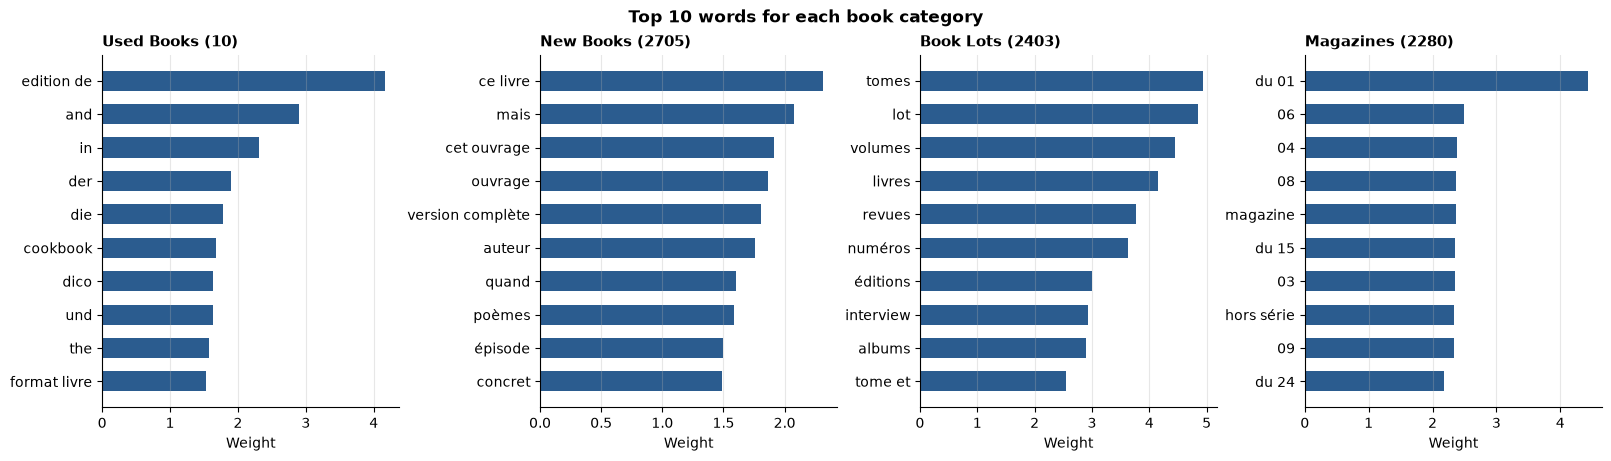

,Used Books,New Books,Book Lots,Magazines
Word,,,,
livre,0.04,0.16,1.97,-1.43
tome,0.77,0.51,1.34,-1.10
edition,0.03,-0.99,0.19,-0.55
édition,0.70,-0.50,0.79,-1.16
roman,0.24,0.49,0.58,0.44
auteur,-0.18,1.75,-0.45,-0.64
collection,0.30,-1.20,1.00,-0.48


In [3]:
book_codes = [10, 2705, 2403, 2280]

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), constrained_layout=True)
for ax, code_ in zip(axes, book_codes):
    row = weights[classes.index(code_)]
    top = np.argsort(row)[::-1][:10]
    ax.barh(words[top][::-1], row[top][::-1], color="#2b5c8f", height=0.6)
    ax.set_title(f"{CATEGORY_NAMES[code_]} ({code_})", loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel("Weight")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
fig.suptitle("Top 10 words for each book category", fontsize=12, fontweight="bold")
plt.show()

# Weight of common book words in each book category
common_words = ["livre", "tome", "edition", "édition", "roman", "auteur", "collection"]
word_index = {w: i for i, w in enumerate(words)}
common = pd.DataFrame(
    {CATEGORY_NAMES[c]: [weights[classes.index(c)][word_index[w]] for w in common_words if w in word_index] for c in book_codes},
    index=[w for w in common_words if w in word_index],
)
common.index.name = "Word"
common.style.format(precision=2)

### Analysis

- Each book category has its own strong words: *tomes*, *lot*, *volumes* for Book Lots, dates like *du 01* for Magazines, summary words for New Books, foreign words for Used Books.
- The common book words are weak and split across categories. *Roman* has almost the same weight (0.24 to 0.58) in all four. *Tome* and *édition* point to both Used Books and Book Lots.
- So a book title without one of the strong words (no "lot", no date, no summary) gives the model almost nothing to decide with. This is why book categories make 7 of the top 10 confused pairs.

### A4. One wrong prediction explained

We take a used book (10) that the model predicted as a book lot (2403). For each word in the product, its contribution to a category is its TF-IDF value times its weight. We compare the words that pushed toward the wrong category and toward the true one.

Title: la promenade au parc


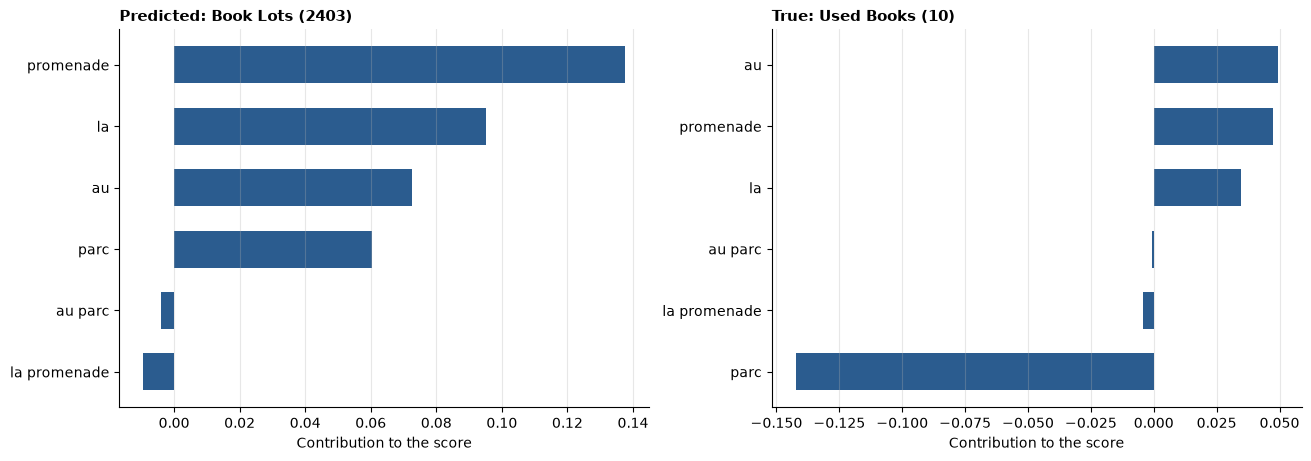

Score for Book Lots (2403): -0.50
Score for Used Books (10):  -0.68


In [4]:
predictions = model.predict(X_validation)
wrong = np.where((validation["prdtypecode"].to_numpy() == 10) & (predictions == 2403))[0]
idx = wrong[0]

x = X_validation[idx]
present = x.indices
print("Title:", validation["designation_clean"].iloc[idx])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for ax, code_, label in [(axes[0], 2403, "Predicted"), (axes[1], 10, "True")]:
    contrib = x.data * weights[classes.index(code_)][present]
    order = np.argsort(contrib)[::-1][:8]
    ax.barh(words[present][order][::-1], contrib[order][::-1], color="#2b5c8f", height=0.6)
    ax.set_title(f"{label}: {CATEGORY_NAMES[code_]} ({code_})", loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel("Contribution to the score")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
plt.show()

scores = model.decision_function(x)[0]
print(f"Score for Book Lots (2403): {scores[classes.index(2403)]:.2f}")
print(f"Score for Used Books (10):  {scores[classes.index(10)]:.2f}")

### Analysis

- The product is a used book with only a short title: *la promenade au parc*. It has no description.
- No word in it is a book word. The model only sees *promenade*, *la*, *au* and *parc*.
- Both scores are negative (-0.50 for Book Lots, -0.68 for Used Books), so the model is not confident in any category. Book Lots wins by a small margin, mainly because of *promenade*. *Parc* pushes away from Used Books.
- This shows a limit of text models: when the text is short and generic, there is not enough information. The image can help in these cases (see notebook 04).

### A5. Which words CamemBERT relies on

CamemBERT has no weight per word, so we use a simple test: remove one word at a time and see how much CamemBERT's confidence in its answer drops. A big drop means the word mattered.

Two short titles from the validation set:
- **les chemins de maison haute 1 & 2** (Book Lots): CamemBERT is right, the SVM says Used Books.
- **chaos chosen age of sigmar** (Wargames): the SVM is right, CamemBERT says Games.

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

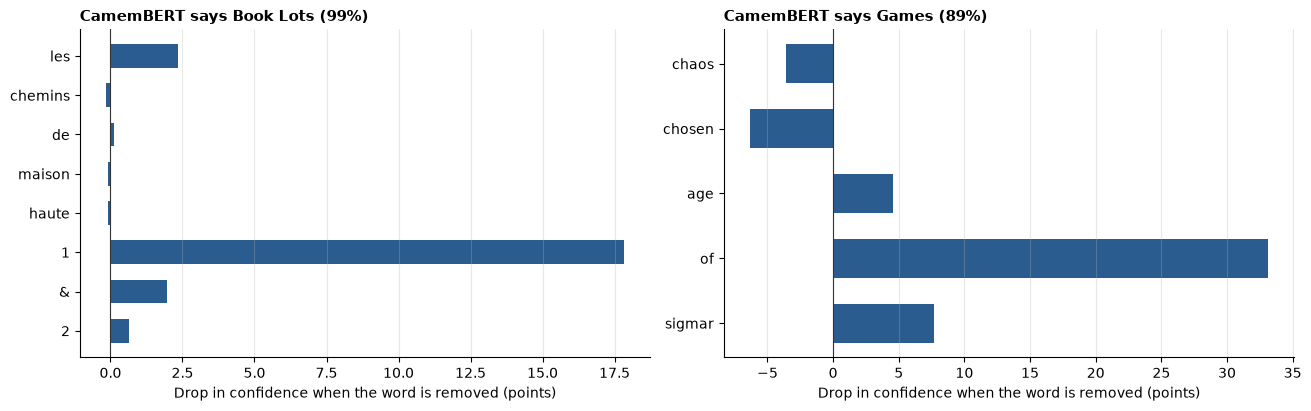

In [5]:
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("../models/camembert")
camembert = AutoModelForSequenceClassification.from_pretrained("../models/camembert").eval()


def camembert_probabilities(texts):
    with torch.no_grad():
        tokens = tokenizer(texts, padding=True, truncation=True, max_length=128, return_tensors="pt")
        return torch.softmax(camembert(**tokens).logits, dim=1).numpy()


def word_importance(text):
    """Drop in confidence for the predicted category when each word is removed."""
    words_in_text = text.split()
    full = camembert_probabilities([text])[0]
    predicted = int(full.argmax())
    without = camembert_probabilities([" ".join(words_in_text[:i] + words_in_text[i + 1:]) for i in range(len(words_in_text))])
    drops = (full[predicted] - without[:, predicted]) * 100
    return words_in_text, drops, classes[predicted], full[predicted]


examples = ["les chemins de maison haute 1 & 2", "chaos chosen age of sigmar"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
for ax, text in zip(axes, examples):
    words_in_text, drops, predicted_code, confidence = word_importance(text)
    ax.barh(words_in_text[::-1], drops[::-1], color="#2b5c8f", height=0.6)
    ax.axvline(0, color="#333333", linewidth=0.8)
    ax.set_title(f"CamemBERT says {CATEGORY_NAMES[predicted_code]} ({confidence:.0%})", loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel("Drop in confidence when the word is removed (points)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", alpha=0.3)
plt.show()

### Analysis

- **Book Lots, CamemBERT right:** removing *1* lowers its confidence by 18 points; every other word matters little. CamemBERT reads *1 & 2* as "volumes 1 and 2", which means a lot of several books. The SVM only counts words, and none of these words is a strong Book Lots word.
- **Wargames, CamemBERT wrong:** the word that matters most is *of* (33 points). CamemBERT reads *age of ...* as a video game title pattern, like *Age of Empires*. The SVM gets it right because of *sigmar*, a rare Warhammer word that appears in only 20 training products.
- So the two text models fail on different products: CamemBERT uses the meaning of the words together, the SVM uses rare exact words. This is why combining them helps in the fusion.

#### Text conclusion

- The text model relies on clear, specific words, which explains its good overall score.
- It also learned seller names and writing style, which may not hold for new sellers.
- Book categories share weak, common words. Short book titles without a strong word are the main source of errors.
- CamemBERT reads words together: *1 & 2* points to a book lot. But a familiar pattern can mislead it, as *age of* did for a Wargames product.


## B. Image

The image model used here is the ResNet18 baseline (notebook 03_modeling_image).

**Grad-CAM** shows which part of an image made the model choose a category. It looks at the last convolution layer, measures how much each region pushes the score of the chosen category up, and draws this as a heatmap: red means important, blue means ignored.

In [6]:
import torch
import torch.nn.functional as F
from PIL import Image
from torch import nn
from torchvision import transforms
from torchvision.models import ResNet18_Weights, resnet18

from src.data_utils import get_image_path, load_merged_data

checkpoint = torch.load("../models/resnet18_image_baseline.pt", map_location="cpu", weights_only=False)
class_to_index = checkpoint["class_to_index"]
index_to_class = {i: c for c, i in class_to_index.items()}

image_model = resnet18()
image_model.fc = nn.Linear(512, len(class_to_index))
image_model.load_state_dict(checkpoint["model_state_dict"])
image_model.eval()

model_input = ResNet18_Weights.DEFAULT.transforms()
as_displayed = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])

saved = {}
image_model.layer4.register_forward_hook(lambda module, inputs, output: saved.update(activation=output))
image_model.layer4.register_full_backward_hook(lambda module, grad_in, grad_out: saved.update(gradient=grad_out[0]))


def grad_cam(image):
    x = model_input(image).unsqueeze(0)
    scores = image_model(x)
    probabilities = torch.softmax(scores, dim=1)[0]
    predicted = int(scores.argmax())
    image_model.zero_grad()
    scores[0, predicted].backward()
    weights = saved["gradient"].mean(dim=(2, 3), keepdim=True)
    heatmap = F.relu((weights * saved["activation"]).sum(dim=1, keepdim=True))
    heatmap = F.interpolate(heatmap, size=(224, 224), mode="bilinear", align_corners=False)[0, 0]
    heatmap = (heatmap / (heatmap.max() + 1e-8)).detach().numpy()
    return heatmap, index_to_class[predicted], probabilities[predicted].item()

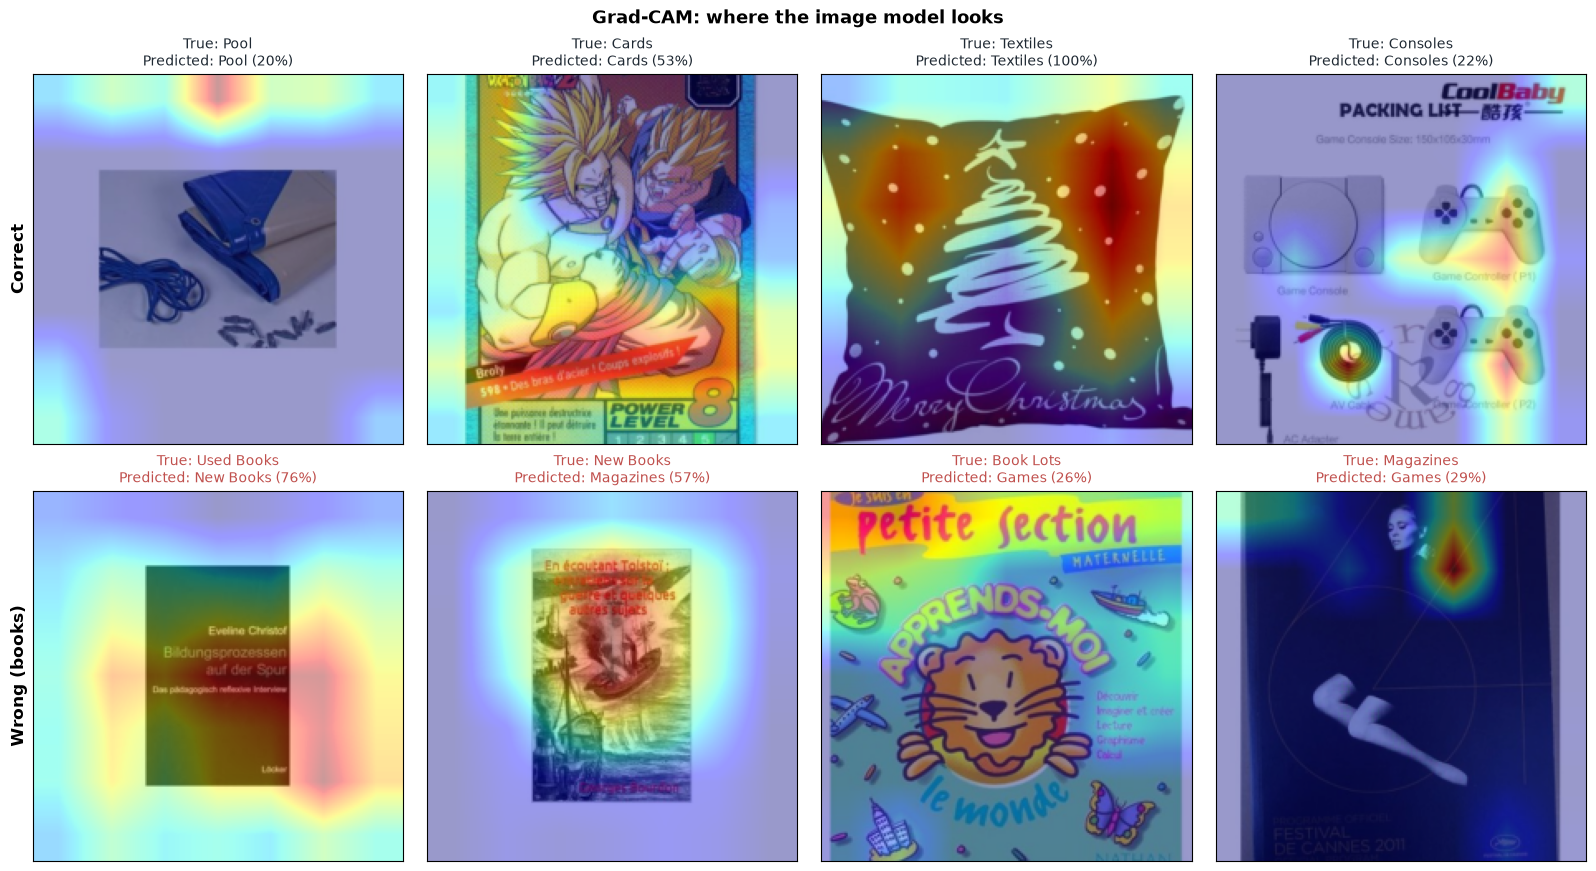

In [7]:
raw = load_merged_data()
image_predictions = pd.read_csv("../data/processed/image_validation_predictions.csv")
image_predictions.columns = [c.strip() for c in image_predictions.columns]

correct = image_predictions[image_predictions["true_prdtypecode"] == image_predictions["predicted_prdtypecode"]]
wrong = image_predictions[image_predictions["true_prdtypecode"] != image_predictions["predicted_prdtypecode"]]

# Correct: one product from 4 categories the image model handles well
# Wrong: one book product from 4 book categories
examples = (
    [correct[correct["true_prdtypecode"] == code].iloc[0] for code in [2583, 1160, 1920, 60]]
    + [wrong[wrong["true_prdtypecode"] == code].iloc[0] for code in [10, 2705, 2403, 2280]]
)

fig, axes = plt.subplots(2, 4, figsize=(16, 8.6), constrained_layout=True)
for ax, row in zip(axes.ravel(), examples):
    product = raw.loc[row["row_id"]]
    image = Image.open(get_image_path(product["imageid"], product["productid"])).convert("RGB")
    heatmap, predicted, probability = grad_cam(image)
    ax.imshow(as_displayed(image))
    ax.imshow(heatmap, cmap="jet", alpha=0.4)
    ax.set_xticks([])
    ax.set_yticks([])
    true_code = int(row["true_prdtypecode"])
    ok = predicted == true_code
    ax.set_title(
        f"True: {CATEGORY_NAMES[true_code]}\nPredicted: {CATEGORY_NAMES[predicted]} ({probability:.0%})",
        fontsize=10, color="#1f2933" if ok else "#c0504d",
    )
axes[0, 0].set_ylabel("Correct", fontsize=12, fontweight="bold")
axes[1, 0].set_ylabel("Wrong (books)", fontsize=12, fontweight="bold")
fig.suptitle("Grad-CAM: where the image model looks", fontsize=13, fontweight="bold")
plt.show()

### Analysis

- When the image model is right, the heatmap is on the product itself: the pillow surface for Textiles, the card for Cards, the controller and cable for Consoles.
- For Pool, it is right with only 20% confidence and looks mostly at the background: a lucky guess rather than a clear signal.
- On books, it looks at the whole cover, which is just a printed rectangle. A used book, a new book and a magazine look alike, so the model confuses them.
- A colourful school book cover (Book Lots) is predicted as a video game, because it looks like a game box.
- These heatmaps use the ResNet18 baseline (0.48).

## C. Fusion

The final model is a Random Forest that takes 81 inputs: 27 probabilities from CamemBERT, 27 from the SVM and 27 from the ConvNeXt image model (notebook 04). We look at it in two ways:

1. **Feature importance:** how often, and how usefully, the trees split on the inputs of each model.
2. **Image contribution per category:** the same Random Forest with and without the image, scored with the same 5-fold cross-validation as in notebook 04.

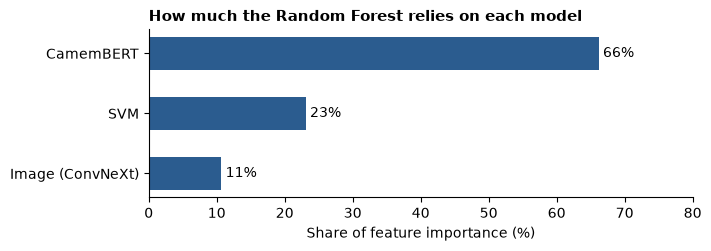

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold

from src.metrics import compute_per_class_metrics

classes_str = [str(c) for c in classes]
fusion = validation[["row_id", "prdtypecode"]].merge(
    pd.read_csv("../data/processed/camembert_validation_probabilities.csv"), on="row_id")
P_camembert = fusion[classes_str].to_numpy()
P_svm = fusion[["row_id"]].merge(
    pd.read_csv("../data/processed/text_validation_probabilities.csv"), on="row_id")[classes_str].to_numpy()
convnext = pd.read_csv("../models/outputs/03_7_convnext_tiny_optimized_validation_predictions.csv")
convnext.columns = [c.strip() for c in convnext.columns]
P_image = fusion[["row_id"]].merge(convnext, on="row_id")[[f"prob_{c}" for c in classes]].to_numpy()
y_fusion = fusion["prdtypecode"].to_numpy()

X_all = np.hstack([P_camembert, P_svm, P_image])
forest = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=42).fit(X_all, y_fusion)

importance = forest.feature_importances_
share = pd.Series({
    "CamemBERT": importance[:27].sum(),
    "SVM": importance[27:54].sum(),
    "Image (ConvNeXt)": importance[54:].sum(),
}).sort_values()

fig, ax = plt.subplots(figsize=(7, 2.4), constrained_layout=True)
bars = ax.barh(share.index, share.values * 100, color="#2b5c8f", height=0.55)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in share.values], padding=3)
ax.set_xlim(0, 80)
ax.set_title("How much the Random Forest relies on each model", loc="left", fontsize=11, fontweight="bold")
ax.set_xlabel("Share of feature importance (%)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

Weighted F1 with image:    0.8988
Weighted F1 without image: 0.8873


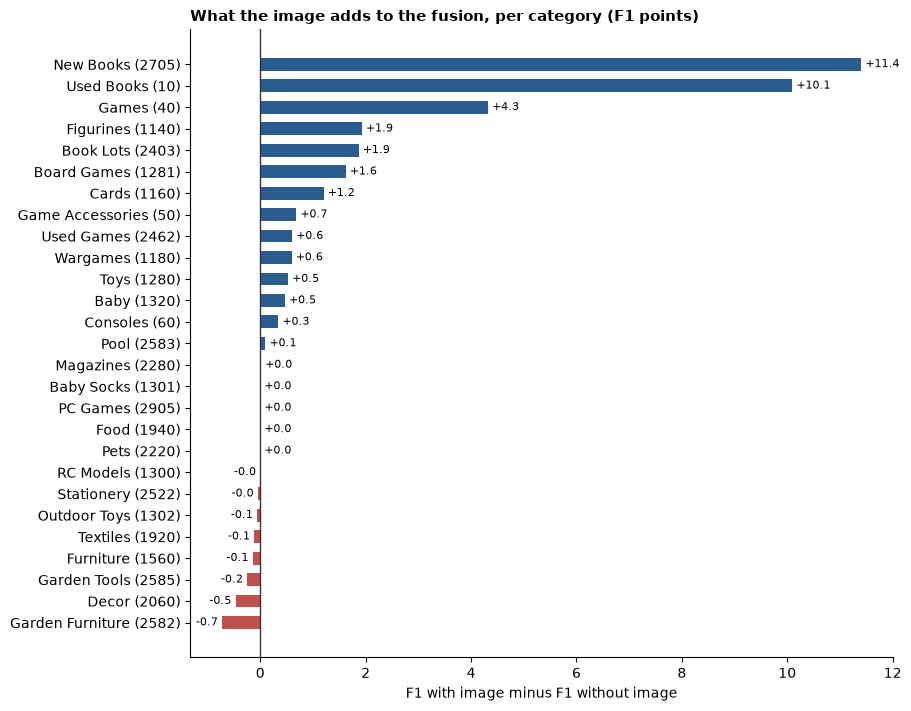

In [9]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def cross_validated(X):
    pred = np.zeros_like(y_fusion)
    for train_idx, test_idx in folds.split(X, y_fusion):
        model = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=42)
        pred[test_idx] = model.fit(X[train_idx], y_fusion[train_idx]).predict(X[test_idx])
    return pred

with_image = cross_validated(X_all)
without_image = cross_validated(np.hstack([P_camembert, P_svm]))
print(f"Weighted F1 with image:    {f1_score(y_fusion, with_image, average='weighted'):.4f}")
print(f"Weighted F1 without image: {f1_score(y_fusion, without_image, average='weighted'):.4f}")

gain = (compute_per_class_metrics(y_fusion, with_image, classes)["f1"].to_numpy()
        - compute_per_class_metrics(y_fusion, without_image, classes)["f1"].to_numpy()) * 100
gain = pd.Series(gain, index=[f"{CATEGORY_NAMES[c]} ({c})" for c in classes]).sort_values()

fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
bars = ax.barh(gain.index, gain.values, color=["#2b5c8f" if g >= 0 else "#c0504d" for g in gain.values], height=0.6)
ax.bar_label(bars, labels=[f"{g:+.1f}" for g in gain.values], padding=3, fontsize=8)
ax.axvline(0, color="#333333", linewidth=1)
ax.set_title("What the image adds to the fusion, per category (F1 points)", loc="left", fontsize=11, fontweight="bold")
ax.set_xlabel("F1 with image minus F1 without image")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Analysis

- The Random Forest relies mostly on CamemBERT (about two thirds of the importance), then on the SVM (23%), then on the image (11%).
- Without the image, the fusion scores 0.8873. With it, 0.8988 (+1.2 points).
- The image adds almost everything on two categories: New Books (+11.4 points) and Used Books (+10.1). Text cannot tell if a book is new or used; the photo can (a clean cover image against a photo of an old copy).
- It also helps on Games (+4.3), where the box picture shows what the text does not say.
- For most other categories the image adds nothing or very little. Its small losses (at most -0.7 points) are within noise.

## Conclusion

- **Text:** the SVM relies on clear product words, but also on seller names and writing style.
- **Image:** the image model looks at the product when it is right, but book covers all look alike to it.
- **Fusion:** CamemBERT does most of the work. The image adds little overall, but it is decisive for telling new books from used books.